In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import ticker

In [47]:
studio = "FitX_Paderborn"
df = pd.read_csv(studio + "_hourly_utilization.csv")
df["start"] = pd.to_datetime(df["start"], utc=True).dt.tz_convert("Europe/Berlin")
df["end"] = pd.to_datetime(df["end"], utc=True).dt.tz_convert("Europe/Berlin")
df

,start,end,mean
0,2025-02-10 12:00:00+01:00,2025-02-10 13:00:00+01:00,20.064864
1,2025-02-10 13:00:00+01:00,2025-02-10 14:00:00+01:00,25.158270
2,2025-02-10 14:00:00+01:00,2025-02-10 15:00:00+01:00,26.937535
3,2025-02-10 15:00:00+01:00,2025-02-10 16:00:00+01:00,28.759990
4,2025-02-10 16:00:00+01:00,2025-02-10 17:00:00+01:00,43.964617
...,...,...,...
14390,2026-10-27 16:00:00+01:00,2026-10-27 17:00:00+01:00,58.331747
14391,2026-10-27 17:00:00+01:00,2026-10-27 18:00:00+01:00,73.499976
14392,2026-10-27 18:00:00+01:00,2026-10-27 19:00:00+01:00,74.042855
14393,2026-10-27 19:00:00+01:00,2026-10-27 20:00:00+01:00,75.749898


In [ ]:
weekdayNames = {
    0: "Mo",
    1: "Di",
    2: "Mi",
    3: "Do",
    4: "Fr",
    5: "Sa",
    6: "So"
}

df = df.set_index("start")
df

,end,mean
start,,
2025-02-10 12:00:00+01:00,2025-02-10 13:00:00+01:00,20.064864
2025-02-10 13:00:00+01:00,2025-02-10 14:00:00+01:00,25.158270
2025-02-10 14:00:00+01:00,2025-02-10 15:00:00+01:00,26.937535
2025-02-10 15:00:00+01:00,2025-02-10 16:00:00+01:00,28.759990
2025-02-10 16:00:00+01:00,2025-02-10 17:00:00+01:00,43.964617
...,...,...
2026-10-27 16:00:00+01:00,2026-10-27 17:00:00+01:00,58.331747
2026-10-27 17:00:00+01:00,2026-10-27 18:00:00+01:00,73.499976
2026-10-27 18:00:00+01:00,2026-10-27 19:00:00+01:00,74.042855


In [54]:
by_weekday_hour = (
    df.groupby([df.index.hour.rename("hour"), df.index.day_of_week.rename("day_of_week")])["mean"]
    .mean()
    .unstack()
    .rename(columns=weekdayNames)
)
by_weekday_hour

day_of_week,Mo,Di,Mi,Do,Fr,Sa,So
hour,,,,,,,
0,7.677755,11.854860,12.555976,11.881259,10.846876,11.327630,9.743201
1,4.444204,6.347321,6.219364,6.620717,6.025778,5.952675,5.891420
2,2.160325,3.093828,3.142983,3.219257,2.749117,2.785890,3.078646
3,1.019682,1.418412,1.680652,1.376577,1.368770,1.090221,1.273179
4,1.515151,1.876176,1.777501,1.589845,1.630650,0.566215,0.456870
5,4.801953,5.366999,4.686203,4.275755,4.049074,1.353921,0.537954
6,9.628789,10.702554,9.664207,8.561314,7.936809,3.291982,1.877831
7,11.284924,12.692395,11.807758,10.223940,10.451102,6.978373,5.409181
8,14.494057,15.873714,15.358187,13.604612,14.285099,12.287318,9.588379


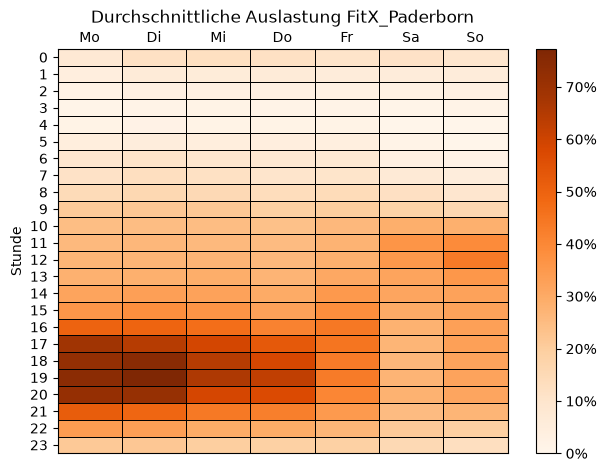

In [55]:
# Auslastung Heatmap
fig, ax = plt.subplots()

colormap = plt.get_cmap('Oranges')

c = ax.pcolormesh(by_weekday_hour, cmap=colormap, shading='nearest', vmin=0)
c.set_edgecolor('black')
c.set_linewidth(0.5)
cbar = fig.colorbar(c, ax=ax)
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x)}%'))
ax.set_yticks(range(len(by_weekday_hour.index)), labels=by_weekday_hour.index)
ax.set_xticks(range(len(by_weekday_hour.columns)), labels=by_weekday_hour.columns)
ax.set_ylabel("Stunde")
ax.set_title(f"Durchschnittliche Auslastung {studio}")
ax.invert_yaxis()
fig.tight_layout()
ax.xaxis.set_ticks_position('top')
ax.xaxis.set_tick_params(width=0, pad=-1)
plt.show()

Text(0, 0.5, 'Auslastung zur Peak Time in %')

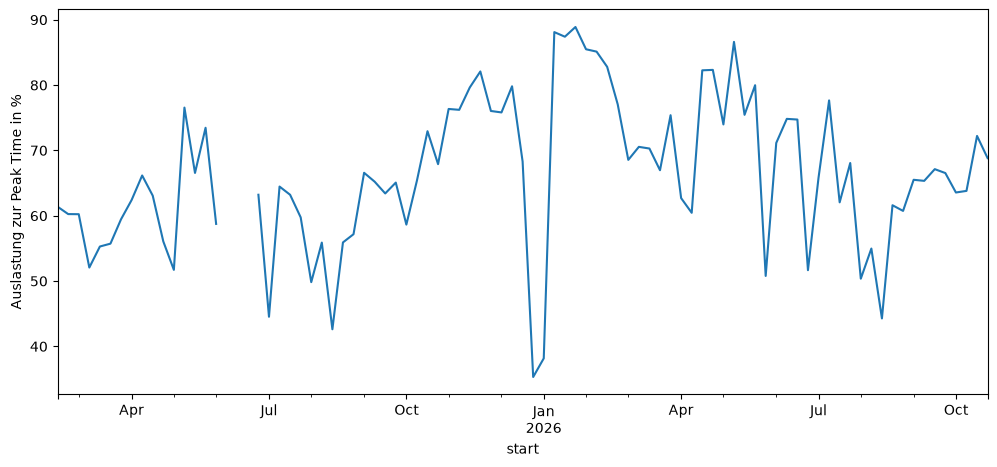

In [165]:
# Development of the utilization in the peak time (Mon-Thu from 17:00 to 20:59)
window_df = df[(df.index.hour.isin(range(17,20))) & (df.index.day_of_week < 4)] 
period_mean = window_df["mean"].resample("W-SUN").mean()
period_mean = period_mean.iloc[:-1] # ignore last period, data for this period is incomplete

ax = period_mean.plot(kind="line", figsize=(12,5))
ax.set_ylabel("Auslastung zur Peak Time in %")